# Improving the models and testing examples

After the model comparison, I ask whether different inputs or more positive training examples change the results. I test feature selection, PCA, the ABS indicator and two sampling methods.

I then load the fitted models and try random readings from the same dataset. This lets me compare their outputs one example at a time.


## Data and libraries

The analysis uses Python for data preparation, modelling and visualization. The dataset and saved results share one project folder. Colab stores this folder in Google Drive, while a local Jupyter session uses the same layout.


In [1]:
from pathlib import Path
import sys
import json
import hashlib
import subprocess
from importlib.metadata import version, PackageNotFoundError
from urllib.request import urlretrieve

packages = {
    "numpy": "2.2.6", "pandas": "2.3.3", "scipy": "1.16.2",
    "scikit-learn": "1.7.2", "xgboost": "3.0.5",
    "imbalanced-learn": "0.14.0", "matplotlib": "3.10.6",
    "seaborn": "0.13.2", "openpyxl": "3.1.5", "joblib": "1.6.0"
}
install = []
for package, required in packages.items():
    try:
        installed = version(package)
    except PackageNotFoundError:
        installed = None
    if installed != required:
        install.append(f"{package}=={required}")
if install:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *install])

try:
    from google.colab import drive
except ImportError:
    project = Path.cwd()
    if project.name == "notebooks":
        project = project.parent
else:
    drive.mount("/content/drive")
    project = Path("/content/drive/MyDrive/Automotive_Component_Failure")

for folder in ["data", "models/baseline", "models/follow_up",
               "results/tables", "results/figures", "results/predictions", "results/recorded"]:
    (project / folder).mkdir(parents=True, exist_ok=True)

source = "https://raw.githubusercontent.com/PrasadKolkar/critical-automotive-component-failure/main"
files = {
    "data/synthetic_telemetry_data.xlsx": "data/synthetic_telemetry_data.xlsx",
    "data/vehicle_folds.csv": "data/vehicle_folds.csv"
}
for name in ["model_comparison.csv", "oof_predictions.csv", "representation_comparison.csv",
             "augmentation_comparison.csv", "confusion_counts.csv"]:
    files["results/recorded/" + name] = "results/recorded/" + name
for name in ["feature_importance.csv", "descriptive_subtype_rules.json", "reconstruction_comparison.json"]:
    files["results/recorded/" + name] = "results/recorded/" + name
for destination, original in files.items():
    if not (project / destination).exists():
        temporary = (project / destination).with_suffix(".download")
        urlretrieve(f"{source}/{original}", temporary)
        temporary.replace(project / destination)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from IPython.display import display

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 20)
figures = project / "results/figures"
tables = project / "results/tables"
recorded = project / "results/recorded"
print("Project files ready.")


Project files ready.


In [2]:
data_path = project / "data/synthetic_telemetry_data.xlsx"
fold_path = project / "data/vehicle_folds.csv"
expected_hashes = {
    data_path: "569d9f3bfd57f25e2ee7b0d4176fd22b8b8e4aa9a1cf5dab30b57517a4950cc3",
    fold_path: "3f9d35b1ba22f124fe4ef11da399b1abe6d8978257025e5cbe7b79b4422b4b1e"
}
for path, expected in expected_hashes.items():
    if hashlib.sha256(path.read_bytes()).hexdigest() != expected:
        raise ValueError(f"The study file has changed: {path.name}")

df = pd.read_excel(data_path)
component_labels = ["engine_failure_imminent", "brake_issue_imminent", "battery_issue_imminent"]
target = "any_imminent_issue"
df[target] = df[component_labels].max(axis=1).astype(int)
vehicle_folds = pd.read_csv(fold_path)
fold_for_row = df.vehicle_id.map(vehicle_folds.set_index("vehicle_id").fold)
assert vehicle_folds.vehicle_id.is_unique
assert set(vehicle_folds.vehicle_id) == set(df.vehicle_id)
assert len(df) == 1970 and df.vehicle_id.nunique() == 50 and df[target].sum() == 35
assert not fold_for_row.isna().any()
print(f"{len(df):,} readings from {df.vehicle_id.nunique()} vehicles")
print(f"{df[target].sum()} issue-labelled readings from {df.loc[df[target].eq(1), 'vehicle_id'].nunique()} vehicles")


1,970 readings from 50 vehicles
35 issue-labelled readings from 25 vehicles


## Preparing the measurements

I combine the engine, brake and battery labels into one outcome. Failure date, failure type and the original issue flags reveal that outcome, so I leave them out of the inputs. Vehicle ID keeps the groups together. Brand is encoded as categories. Scaling and other fitted steps use training readings only.


In [3]:
import time
import warnings
from itertools import product
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (precision_score, recall_score, f1_score, average_precision_score,
                             confusion_matrix, precision_recall_curve)
from sklearn.model_selection import ParameterGrid
from xgboost import XGBClassifier
from imblearn.over_sampling import RandomOverSampler, SMOTENC
from threadpoolctl import threadpool_limits

excluded = ["vehicle_id", "timestamp", "failure_date", "failure_type", target, *component_labels]
predictors = [column for column in df.columns if column not in excluded + ["abs_fault_indicator"]]
numeric_columns = df[predictors].select_dtypes(include="number").columns.tolist()
categorical_columns = ["brand"]
assert len(numeric_columns) == 32 and len(predictors) == 33
print("Predictors:", len(numeric_columns), "numeric measurements and brand")


Predictors: 32 numeric measurements and brand


## Keeping vehicles together

I use five fixed vehicle groups. Each round holds out ten vehicles and seven issue readings. Within the remaining vehicles, three smaller groups help choose the model settings.


In [4]:
split_summary = pd.DataFrame({"fold": fold_for_row, "vehicle": df.vehicle_id, "issues": df[target]})
display(split_summary.groupby("fold").agg(readings=("vehicle", "size"), vehicles=("vehicle", "nunique"), issues=("issues", "sum")))


,readings,vehicles,issues
fold,,,
1,396,10,7
2,396,10,7
3,393,10,7
4,393,10,7
5,392,10,7


In [5]:
def grouped_splits(frame, n_splits=3):
    summary = (frame.groupby("vehicle_id").agg(rows=(target, "size"), positives=(target, "sum"))
               .reset_index().sort_values(["positives", "rows", "vehicle_id"], ascending=[False, False, True]))
    groups = [[] for _ in range(n_splits)]
    positive_counts = [0] * n_splits
    row_counts = [0] * n_splits
    for row in summary.itertuples():
        fold = min(range(n_splits), key=lambda i: (positive_counts[i], row_counts[i], len(groups[i])))
        groups[fold].append(row.vehicle_id)
        positive_counts[fold] += row.positives
        row_counts[fold] += row.rows
    splits = []
    for vehicles in groups:
        validation = frame.vehicle_id.isin(vehicles).to_numpy()
        train_index = np.flatnonzero(~validation)
        valid_index = np.flatnonzero(validation)
        assert set(frame.iloc[train_index].vehicle_id).isdisjoint(frame.iloc[valid_index].vehicle_id)
        assert frame.iloc[train_index][target].nunique() == frame.iloc[valid_index][target].nunique() == 2
        splits.append((train_index, valid_index))
    return splits


def evaluate(y, scores):
    predicted = (np.asarray(scores) >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, predicted, labels=[0, 1]).ravel()
    return {"precision": precision_score(y, predicted, zero_division=0),
            "recall": recall_score(y, predicted, zero_division=0),
            "F1": f1_score(y, predicted, zero_division=0),
            "AP": average_precision_score(y, scores),
            "TP": int(tp), "FP": int(fp), "FN": int(fn), "TN": int(tn)}


## Model settings

I compare a linear model, two tree models, SVM, Naive Bayes and a small neural network. The candidate settings follow the study. The ANN grid tries 16 or 32 hidden units and two regularization values.


In [6]:
model_settings = {
    "LR": [dict(C=c, class_weight="balanced", solver="liblinear", max_iter=1000, random_state=42)
           for c in [0.1, 1.0, 10.0]],
    "RF": [
        dict(n_estimators=200, max_depth=4, min_samples_leaf=2, max_features="sqrt",
             class_weight="balanced", random_state=42, n_jobs=1),
        dict(n_estimators=300, max_depth=6, min_samples_leaf=3, max_features="sqrt",
             class_weight="balanced", random_state=42, n_jobs=1),
        dict(n_estimators=300, max_depth=None, min_samples_leaf=5, max_features="sqrt",
             class_weight="balanced_subsample", random_state=42, n_jobs=1)
    ],
    "XGB": [
        dict(n_estimators=80, max_depth=2, learning_rate=.08, subsample=.9, colsample_bytree=.9,
             min_child_weight=1, reg_alpha=0., reg_lambda=1., random_state=42, eval_metric="logloss", n_jobs=1),
        dict(n_estimators=120, max_depth=3, learning_rate=.05, subsample=.9, colsample_bytree=.8,
             min_child_weight=2, reg_alpha=0., reg_lambda=2., random_state=42, eval_metric="logloss", n_jobs=1),
        dict(n_estimators=160, max_depth=2, learning_rate=.04, subsample=.8, colsample_bytree=.8,
             min_child_weight=3, reg_alpha=.1, reg_lambda=2., random_state=42, eval_metric="logloss", n_jobs=1)
    ],
    "SVM": [dict(C=c, kernel="rbf", gamma="scale", class_weight="balanced", probability=False, random_state=42)
            for c in [.1, 1., 10.]] + [dict(C=1., kernel="linear", gamma="scale", class_weight="balanced", probability=False, random_state=42)],
    "NB": [dict(var_smoothing=value) for value in [1e-9, 1e-6, 1e-3]],
    "ANN": [dict(alpha=alpha, hidden_layer_sizes=(units,), solver="lbfgs", activation="relu",
                 max_iter=1000, max_fun=20000, tol=1e-4, early_stopping=False, random_state=42)
            for alpha in [.1, 1.] for units in [16, 32]]
}

model_names = {"LR": "Logistic Regression", "RF": "Random Forest", "XGB": "XGBoost",
               "SVM": "SVM", "NB": "Naive Bayes", "ANN": "ANN"}


def experiment(model, representation="original", include_abs=False, sampler="none", seed=42, weighted=True):
    if model == "NB":
        weighted = False
    params = [p.copy() for p in model_settings[model]]
    if model == "LR":
        params = [dict(p, class_weight="balanced" if weighted else None) for p in params]
    representations = {"original": [None], "selection": [10, 20], "pca": [.90, .95]}[representation]
    ratios = [.10, .25] if sampler != "none" else [None]
    candidates = [{"params": p, "representation_value": r, "ratio": ratio}
                  for p, r, ratio in product(params, representations, ratios)]
    suffix = "abs" if include_abs else "noabs"
    weight_name = "weighted" if weighted else "unweighted"
    identifier = f"{model.lower()}_{suffix}_{representation}_{sampler}_{weight_name}"
    if sampler != "none":
        identifier += f"_seed{seed}"
    name = model_names[model]
    if representation != "original":
        name += " + " + ("selected sensors" if representation == "selection" else "PCA")
    if include_abs:
        name += " + ABS"
    if sampler != "none":
        name += f" + {sampler} (seed {seed})"
    folder = "baseline" if representation == "original" and not include_abs and sampler == "none" and (weighted or model == "NB") else "follow_up"
    return dict(id=identifier, name=name, model=model, representation=representation, abs=include_abs,
                sampler=sampler, seed=seed, weighted=weighted, candidates=candidates, folder=folder)


baseline_configs = [experiment(model) for model in model_names]


## Preparing and fitting each model

Logistic Regression, SVM, Naive Bayes and ANN use scaled numerical inputs. Trees use the original scale. I select sensors or apply PCA inside the numerical pipeline when the experiment calls for it.


In [7]:
def prepare_inputs(config, candidate):
    numbers = numeric_columns + (["abs_fault_indicator"] if config["abs"] else [])
    steps = [("imputer", SimpleImputer(strategy="median"))]
    if config["model"] not in ["RF", "XGB"]:
        steps.append(("scaler", StandardScaler()))
    if config["representation"] == "selection":
        steps.append(("representation", SelectKBest(f_classif, k=candidate["representation_value"])))
    elif config["representation"] == "pca":
        steps.append(("representation", PCA(n_components=candidate["representation_value"], svd_solver="full")))
    categories = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                           ("onehot", OneHotEncoder(handle_unknown="ignore"))])
    return ColumnTransformer([("numeric", Pipeline(steps), numbers),
                              ("brand", categories, categorical_columns)], sparse_threshold=0)


## Adding training examples

Random oversampling repeats existing issue readings. SMOTENC creates nearby examples while treating brand as a category. I keep engine, brake and battery patterns separate. Neighbours come only from training vehicles. Generated values stay within their subtype's observed ranges, although this alone cannot establish physical realism.


In [8]:
def add_training_examples(training, config, ratio):
    columns = predictors + (["abs_fault_indicator"] if config["abs"] else [])
    numbers = numeric_columns + (["abs_fault_indicator"] if config["abs"] else [])
    values = training[columns].copy()
    y = training[target].to_numpy()
    scaler = StandardScaler()
    values[numbers] = scaler.fit_transform(SimpleImputer(strategy="median").fit_transform(values[numbers]))
    values[categorical_columns] = SimpleImputer(strategy="most_frequent").fit_transform(values[categorical_columns])
    subtypes = training[component_labels].astype(int).astype(str).agg("".join, axis=1).to_numpy()
    counts = pd.Series(subtypes[y == 1]).value_counts().sort_index()
    extra_count = max(0, int(np.ceil((y == 0).sum() * ratio)) - int(y.sum()))
    proportions = counts / counts.sum() * extra_count
    quotas = np.floor(proportions).astype(int)
    remainder = extra_count - int(quotas.sum())
    for subtype in (proportions - quotas).sort_values(ascending=False, kind="stable").index[:remainder]:
        quotas[subtype] += 1
    additions = []
    for number, (subtype, count) in enumerate(counts.items()):
        indices = np.flatnonzero((y == 0) | ((y == 1) & (subtypes == subtype)))
        part, labels = values.iloc[indices].reset_index(drop=True), y[indices]
        neighbours = min(3, int(count) - 1)
        settings = {"sampling_strategy": {1: int(count + quotas[subtype])},
                    "random_state": config["seed"] + number}
        if config["sampler"] == "smotenc" and neighbours > 0:
            sampler = SMOTENC(categorical_features=categorical_columns, k_neighbors=neighbours, **settings)
        else:
            sampler = RandomOverSampler(**settings)
        sampled, _ = sampler.fit_resample(part, labels)
        generated = sampled.iloc[len(part):].copy()
        positives = part.loc[labels == 1, numbers]
        assert ((generated[numbers] >= positives.min() - 1e-10)
                & (generated[numbers] <= positives.max() + 1e-10)).all().all()
        assert all(set(generated[c]).issubset(set(part.loc[labels == 1, c])) for c in categorical_columns)
        additions.append(generated)
    generated = pd.concat(additions, ignore_index=True)
    generated[numbers] = scaler.inverse_transform(generated[numbers])
    assert len(generated) == extra_count
    return (pd.concat([training[columns], generated], ignore_index=True),
            np.concatenate([y, np.ones(len(generated), dtype=int)]))


In [9]:
FIT_COUNT = 0


def fit_model(training, config, candidate):
    global FIT_COUNT
    columns = predictors + (["abs_fault_indicator"] if config["abs"] else [])
    X, y = training[columns], training[target].to_numpy()
    params = candidate["params"].copy()
    preprocessing = prepare_inputs(config, candidate)
    with warnings.catch_warnings(record=True) as caught, threadpool_limits(limits=1):
        warnings.simplefilter("always")
        if config["model"] == "SVM":
            pipeline = Pipeline([("preprocess", preprocessing), ("model", SVC(**params))])
            fitted = CalibratedClassifierCV(estimator=pipeline, cv=grouped_splits(training),
                                           method="sigmoid", ensemble=False, n_jobs=1)
            fitted.fit(X, y)
        else:
            if config["model"] == "XGB":
                params["scale_pos_weight"] = float((y == 0).sum() / (y == 1).sum()) if config["weighted"] else 1.0
            constructors = {"LR": LogisticRegression, "RF": RandomForestClassifier,
                            "XGB": XGBClassifier, "NB": GaussianNB, "ANN": MLPClassifier}
            estimator = constructors[config["model"]](**params)
            preprocessing.fit(X, y)
            X_fit, y_fit = X, y
            if config["sampler"] != "none":
                X_fit, y_fit = add_training_examples(training, config, candidate["ratio"])
            weights = {}
            if config["model"] == "ANN" and config["weighted"]:
                weights["sample_weight"] = compute_sample_weight("balanced", y_fit)
            estimator.fit(preprocessing.transform(X_fit), y_fit, **weights)
            fitted = Pipeline([("preprocess", preprocessing), ("model", estimator)])
    FIT_COUNT += 1
    messages = [f"{w.category.__name__}: {w.message}" for w in caught]
    return fitted, messages


def predict(model, readings, config):
    columns = predictors + (["abs_fault_indicator"] if config["abs"] else [])
    with threadpool_limits(limits=1):
        scores = model.predict_proba(readings[columns])[:, 1]
    assert np.isfinite(scores).all() and ((scores >= 0) & (scores <= 1)).all()
    return scores


## Selecting and saving the models

For each fold, I choose settings by average precision, followed by F1 and recall. The chosen model then predicts the held-out vehicles. I save each fitted model with its preprocessing and selected settings. These saved fits support repeated evaluation and example predictions.


In [10]:
data_signature = {p.name: hashlib.sha256(p.read_bytes()).hexdigest() for p in expected_hashes}
actual_versions = {name: version(name) for name in packages}
(project / "environment.json").write_text(json.dumps({"python": sys.version, "packages": actual_versions}, indent=2))


def run_experiment(config):
    folder = project / "models" / config["folder"] / config["id"]
    folder.mkdir(parents=True, exist_ok=True)
    signature = hashlib.sha256(json.dumps({"config": config, "data": data_signature,
                                          "packages": actual_versions}, sort_keys=True).encode()).hexdigest()
    fold_predictions, fold_metrics, choices, search_results, training_warnings = [], [], [], [], []
    trained_count, loaded_count = 0, 0
    for fold in range(1, 6):
        path = folder / f"fold_{fold}.joblib"
        test_mask = fold_for_row.eq(fold)
        training, test = df.loc[~test_mask], df.loc[test_mask]
        assert set(training.vehicle_id).isdisjoint(test.vehicle_id)
        if path.exists():
            saved = joblib.load(path)
            if saved["signature"] != signature:
                raise ValueError("Saved models use different study settings or package versions. Use the listed requirements.")
            assert saved["training_rows"] == training.index.tolist()
            assert saved["test_rows"] == test.index.tolist()
            loaded_count += 1
        else:
            inner_splits = grouped_splits(training)
            candidate_results = []
            for number, candidate in enumerate(config["candidates"]):
                scores = []
                for train_index, valid_index in inner_splits:
                    inner_train, validation = training.iloc[train_index], training.iloc[valid_index]
                    fitted, messages = fit_model(inner_train, config, candidate)
                    result = evaluate(validation[target], predict(fitted, validation, config))
                    scores.append(result)
                means = {key: float(np.mean([row[key] for row in scores])) for key in ["AP", "F1", "recall"]}
                candidate_results.append(dict(candidate=number, **means))
            best = max(candidate_results, key=lambda row: (row["AP"], row["F1"], row["recall"], -row["candidate"]))
            choice = config["candidates"][best["candidate"]]
            fitted, messages = fit_model(training, config, choice)
            saved = {"signature": signature, "model": fitted, "config": config, "choice": choice,
                     "training_rows": training.index.tolist(), "test_rows": test.index.tolist(),
                     "search_results": candidate_results, "warnings": messages}
            temporary = path.with_suffix(".tmp")
            joblib.dump(saved, temporary)
            temporary.replace(path)
            trained_count += 1
        scores = predict(saved["model"], test, config)
        fold_metrics.append(dict(fold=fold, **evaluate(test[target], scores)))
        fold_predictions.append(pd.DataFrame({"row_index": test.index, "vehicle_id": test.vehicle_id.to_numpy(),
            "fold": fold, "actual": test[target].to_numpy(), "score": scores, "predicted": (scores >= .5).astype(int)}))
        choices.append(dict(fold=fold, choice=saved["choice"]))
        search_results.extend(dict(fold=fold, **row) for row in saved["search_results"])
        training_warnings.extend(dict(fold=fold, warning=message) for message in saved["warnings"])
    predictions = pd.concat(fold_predictions).sort_values("row_index").reset_index(drop=True)
    assert predictions.row_index.tolist() == df.index.tolist()
    summary = dict(id=config["id"], model=config["model"], name=config["name"],
                   **evaluate(predictions.actual, predictions.score))
    predictions.to_csv(project / "results/predictions" / f"{config['id']}.csv", index=False)
    pd.DataFrame(fold_metrics).to_csv(tables / f"{config['id']}_folds.csv", index=False)
    pd.DataFrame(search_results).to_csv(tables / f"{config['id']}_search.csv", index=False)
    pd.DataFrame(training_warnings, columns=["fold", "warning"]).to_csv(tables / f"{config['id']}_warnings.csv", index=False)
    (tables / f"{config['id']}_settings.json").write_text(json.dumps(choices, indent=2))
    print(f"{config['name']}: {trained_count} folds trained, {loaded_count} loaded.")
    return summary, predictions


## Baseline comparison

The six model families provide the reference for the follow-up experiments. Each uses the original inputs without the ABS indicator. All comparisons use the same vehicle groups.


In [11]:
baseline_results = {}
for config in baseline_configs:
    result, _ = run_experiment(config)
    baseline_results[config["model"]] = result
baseline = pd.DataFrame(baseline_results.values())
display(baseline[["name", "F1", "AP", "TP", "FP", "FN"]].round(4))


Logistic Regression: 0 folds trained, 5 loaded.


Random Forest: 0 folds trained, 5 loaded.


XGBoost: 0 folds trained, 5 loaded.
SVM: 0 folds trained, 5 loaded.
Naive Bayes: 0 folds trained, 5 loaded.


ANN: 0 folds trained, 5 loaded.


,name,F1,AP,TP,FP,FN
0,Logistic Regression,0.4776,0.8427,32,67,3
1,Random Forest,0.4444,0.9656,10,0,25
2,XGBoost,0.8947,0.9730,34,7,1
3,SVM,0.9444,0.9896,34,3,1
4,Naive Bayes,0.4960,0.8747,31,59,4
5,ANN,0.9315,0.9895,34,4,1


## Does choosing fewer sensors help?

Feature selection keeps measured variables that separate the training labels. PCA instead combines numerical measurements into directions that preserve overall variation. I expect these approaches to behave differently because the issue class is small.

I compare both with the original inputs for Logistic Regression and ANN. Selection tries ten or 20 numerical variables. PCA tries 90% or 95% retained variation. Brand is encoded separately.


Logistic Regression + selected sensors: 0 folds trained, 5 loaded.
Logistic Regression + PCA: 0 folds trained, 5 loaded.
ANN + selected sensors: 0 folds trained, 5 loaded.
ANN + PCA: 0 folds trained, 5 loaded.


,name,F1,AP,TP,FP,FN
0,Logistic Regression,0.4776,0.8427,32,67,3
5,ANN,0.9315,0.9895,34,4,1
6,Logistic Regression + selected sensors,0.5152,0.8894,34,63,1
7,Logistic Regression + PCA,0.5082,0.8267,31,56,4
8,ANN + selected sensors,0.9714,0.9909,34,1,1
9,ANN + PCA,0.8611,0.9600,31,6,4


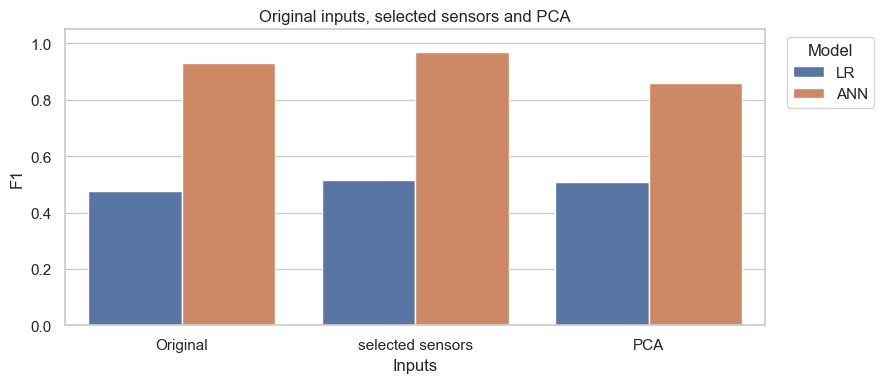

In [12]:
representation_configs = [experiment(model, representation=method)
                          for model in ["LR", "ANN"] for method in ["selection", "pca"]]
representation_results = [run_experiment(config)[0] for config in representation_configs]
representation_table = pd.DataFrame(list(baseline_results.values()) + representation_results)
representation_table = representation_table.loc[representation_table.model.isin(["LR", "ANN"])].copy()
representation_table["Inputs"] = ["Original" if " + " not in name else name.split(" + ")[1] for name in representation_table.name]
display(representation_table[["name", "F1", "AP", "TP", "FP", "FN"]].round(4))
plt.figure(figsize=(9, 4))
sns.barplot(data=representation_table, x="Inputs", y="F1", hue="model")
plt.legend(title="Model", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.ylim(0, 1.05)
plt.title("Original inputs, selected sensors and PCA")
plt.tight_layout()
plt.savefig(figures / "feature_selection_pca.png", dpi=180)
plt.show()


In the recorded study, feature selection reduced the ANN's false alerts from four to one. PCA lowered its F1. The table above shows whether the fresh run follows the same pattern.


## Which sensors were selected?

I count how often each numerical sensor was retained in the five ANN fits. Repeated selection indicates an association with the training labels. A contextual feature such as GPS may also reflect the synthetic generator.


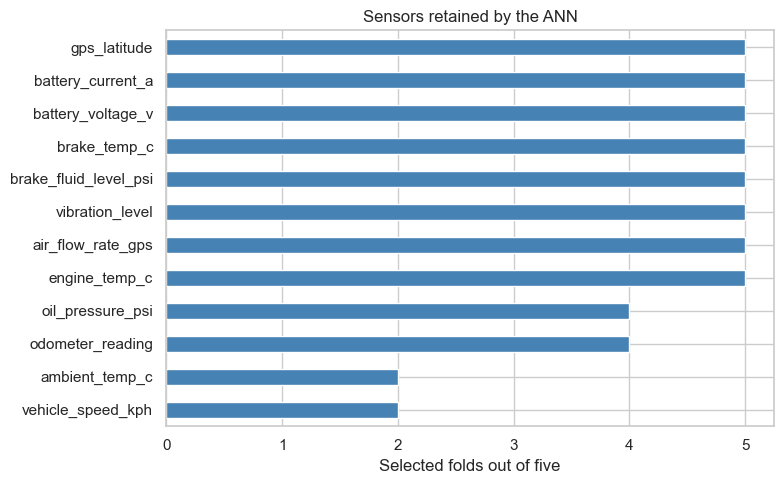

In [13]:
selected_ann = experiment("ANN", representation="selection")
selection_counts = pd.Series(0, index=numeric_columns)
for fold in range(1, 6):
    saved = joblib.load(project / "models/follow_up" / selected_ann["id"] / f"fold_{fold}.joblib")
    selector = saved["model"].named_steps["preprocess"].named_transformers_["numeric"].named_steps["representation"]
    selection_counts.loc[np.array(numeric_columns)[selector.get_support()]] += 1
plt.figure(figsize=(8, 5))
selection_counts.nlargest(12).sort_values().plot.barh(color="steelblue")
plt.xlabel("Selected folds out of five")
plt.title("Sensors retained by the ANN")
plt.tight_layout()
plt.savefig(figures / "selected_sensors.png", dpi=180)
plt.show()


## Does the ABS indicator change the results?

The workbook includes an ABS fault indicator. Its timing relative to a later failure is unclear. I compare the same model families with this input included.


Logistic Regression + ABS: 0 folds trained, 5 loaded.
Random Forest + ABS: 0 folds trained, 5 loaded.


XGBoost + ABS: 0 folds trained, 5 loaded.
SVM + ABS: 0 folds trained, 5 loaded.
Naive Bayes + ABS: 0 folds trained, 5 loaded.
ANN + ABS: 0 folds trained, 5 loaded.


,model,F1 without ABS,AP without ABS,F1 with ABS,AP with ABS
0,LR,0.4776,0.8427,0.4714,0.8443
1,RF,0.4444,0.9656,0.4783,0.9712
2,XGB,0.8947,0.9730,0.9429,0.9872
3,SVM,0.9444,0.9896,0.9444,0.9896
4,NB,0.4960,0.8747,0.4429,0.8713
5,ANN,0.9315,0.9895,0.9296,0.9798


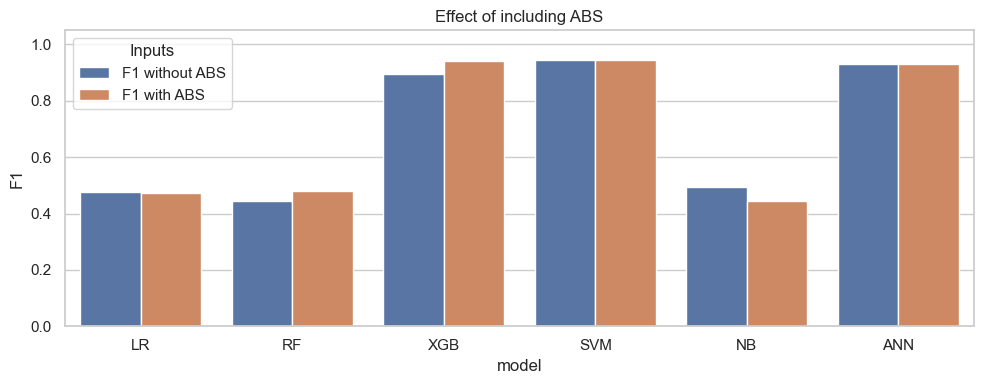

In [14]:
abs_configs = [experiment(model, include_abs=True) for model in model_names]
abs_results = pd.DataFrame([run_experiment(config)[0] for config in abs_configs])
abs_comparison = baseline[["model", "F1", "AP"]].merge(abs_results[["model", "F1", "AP"]], on="model", suffixes=(" without ABS", " with ABS"))
display(abs_comparison.round(4))
abs_plot = abs_comparison.melt(id_vars="model", value_vars=["F1 without ABS", "F1 with ABS"], var_name="Inputs", value_name="F1")
plt.figure(figsize=(10, 4))
sns.barplot(data=abs_plot, x="model", y="F1", hue="Inputs")
plt.ylim(0, 1.05)
plt.title("Effect of including ABS")
plt.tight_layout()
plt.savefig(figures / "abs_comparison.png", dpi=180)
plt.show()


## Can more issue examples help?

I compare random oversampling and SMOTENC for Logistic Regression and XGBoost. Each method uses three sampler seeds: 42, 7 and 2026. The training search tries positive-to-negative ratios of 0.10 and 0.25.

I include unweighted controls as well as the weighted baselines. Sampling changes training only. Every comparison is evaluated on the original held-out readings.


In [15]:
unweighted_configs = [experiment(model, weighted=False) for model in ["LR", "XGB"]]
unweighted_results = pd.DataFrame([run_experiment(config)[0] for config in unweighted_configs])
sampling_configs = [experiment(model, sampler=method, seed=seed, weighted=False)
                    for model, method, seed in product(["LR", "XGB"], ["random_over", "smotenc"], [42, 7, 2026])]
sampling_rows = []
for config in sampling_configs:
    result, _ = run_experiment(config)
    sampling_rows.append(dict(result, method=config["sampler"], seed=config["seed"]))
sampling_results = pd.DataFrame(sampling_rows)
sampling_summary = sampling_results.groupby(["model", "method"]).agg(
    AP_mean=("AP", "mean"), AP_min=("AP", "min"), AP_max=("AP", "max"),
    F1_mean=("F1", "mean"), F1_min=("F1", "min"), F1_max=("F1", "max")).reset_index()
display(unweighted_results[["name", "F1", "AP", "TP", "FP", "FN"]].round(4))
display(sampling_summary.round(4))
sampling_summary.to_csv(tables / "sampling_summary.csv", index=False)


Logistic Regression: 0 folds trained, 5 loaded.
XGBoost: 0 folds trained, 5 loaded.
Logistic Regression + random_over (seed 42): 0 folds trained, 5 loaded.
Logistic Regression + random_over (seed 7): 0 folds trained, 5 loaded.
Logistic Regression + random_over (seed 2026): 0 folds trained, 5 loaded.


Logistic Regression + smotenc (seed 42): 0 folds trained, 5 loaded.
Logistic Regression + smotenc (seed 7): 0 folds trained, 5 loaded.
Logistic Regression + smotenc (seed 2026): 0 folds trained, 5 loaded.
XGBoost + random_over (seed 42): 0 folds trained, 5 loaded.
XGBoost + random_over (seed 7): 0 folds trained, 5 loaded.


XGBoost + random_over (seed 2026): 0 folds trained, 5 loaded.
XGBoost + smotenc (seed 42): 0 folds trained, 5 loaded.
XGBoost + smotenc (seed 7): 0 folds trained, 5 loaded.
XGBoost + smotenc (seed 2026): 0 folds trained, 5 loaded.


,name,F1,AP,TP,FP,FN
0,Logistic Regression,0.7241,0.8347,21,2,14
1,XGBoost,0.9062,0.9870,29,0,6


,model,method,AP_mean,AP_min,AP_max,F1_mean,F1_min,F1_max
0,LR,random_over,0.8467,0.8284,0.8642,0.7551,0.7160,0.8056
1,LR,smotenc,0.8598,0.8474,0.8710,0.7537,0.7317,0.7733
2,XGB,random_over,0.9720,0.9630,0.9856,0.9322,0.9143,0.9412
3,XGB,smotenc,0.9774,0.9739,0.9834,0.9407,0.9091,0.9565


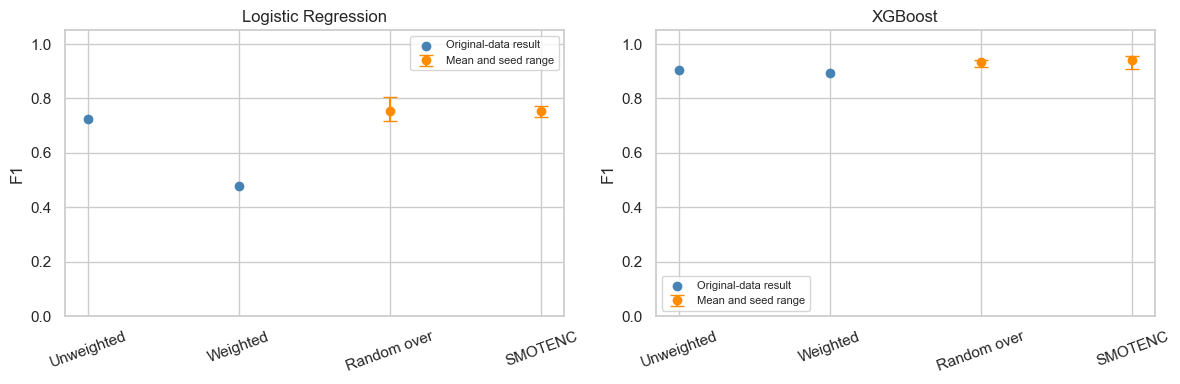

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, model in zip(axes, ["LR", "XGB"]):
    summary = sampling_summary.loc[sampling_summary.model.eq(model)].set_index("method")
    unweighted = unweighted_results.loc[unweighted_results.model.eq(model)].iloc[0].F1
    ax.scatter([0, 1], [unweighted, baseline_results[model]["F1"]], color="steelblue", label="Original-data result")
    for x, method in zip([2, 3], ["random_over", "smotenc"]):
        row = summary.loc[method]
        ax.errorbar(x, row.F1_mean, yerr=[[row.F1_mean - row.F1_min], [row.F1_max - row.F1_mean]],
                    fmt="o", capsize=5, color="darkorange", label="Mean and seed range" if x == 2 else None)
    ax.set(xticks=range(4), xticklabels=["Unweighted", "Weighted", "Random over", "SMOTENC"],
           ylabel="F1", title=model_names[model], ylim=(0, 1.05))
    ax.tick_params(axis="x", rotation=20)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(figures / "sampling_comparison.png", dpi=180)
plt.show()


Capped lines show the lowest and highest scores across the three seeds. They are observed ranges. In the report, neither sampling method improved on weighted XGBoost in both AP and F1. More training rows also do not add independently observed failures.


## Looking more closely at the synthetic patterns

The EDA suggested clear component-related sensor differences. After examining every label, the recorded analysis found cutoffs that separate each component group perfectly. I show those descriptive cutoffs below. They were chosen from the same data being displayed, so their perfect separation is not a new test result.


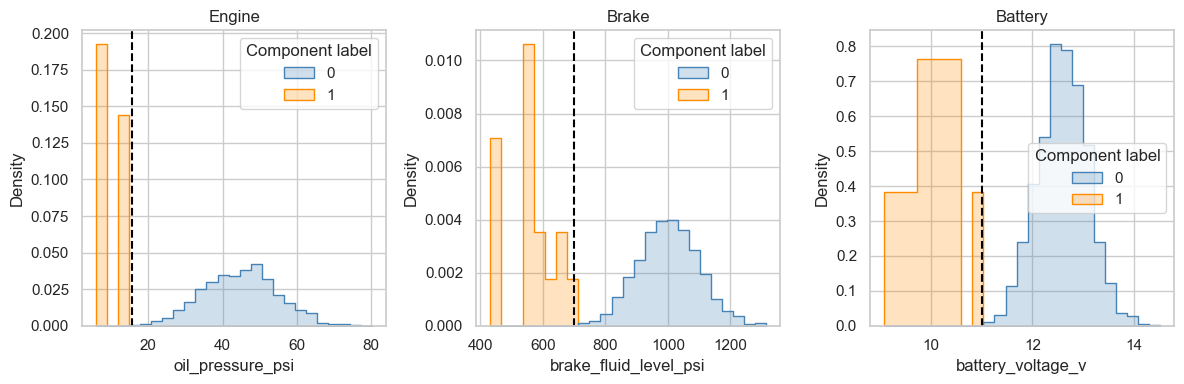

,component,sensor,cutoff,TP,FP,FN
0,engine_failure_imminent,oil_pressure_psi,15.671447,7,0,0
1,brake_issue_imminent,brake_fluid_level_psi,697.959300,16,0,0
2,battery_issue_imminent,battery_voltage_v,10.998107,12,0,0


In [17]:
rules = json.loads((recorded / "descriptive_subtype_rules.json").read_text())["rules"]
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
rule_results = []
for ax, rule in zip(axes, rules):
    sensor, label, cutoff = rule["feature"], rule["target"], rule["threshold"]
    sns.histplot(data=df, x=sensor, hue=label, bins=25, stat="density", common_norm=False,
                 element="step", ax=ax, palette=["steelblue", "darkorange"])
    ax.axvline(cutoff, color="black", linestyle="--")
    ax.set_title(label.split("_")[0].title())
    ax.get_legend().set_title("Component label")
    rule_results.append(dict(component=label, sensor=sensor, cutoff=cutoff, **evaluate(df[label], (df[sensor] <= cutoff).astype(float))))
plt.tight_layout()
plt.savefig(figures / "synthetic_separation.png", dpi=180)
plt.show()
display(pd.DataFrame(rule_results)[["component", "sensor", "cutoff", "TP", "FP", "FN"]])


## Reading the saved XGBoost diagnostic

The original fitted XGBoost models were not saved. The later diagnostic rebuilt them and found different decisions. Its feature-shuffling results describe that rebuild. I keep this recorded analysis alongside the fresh results rather than treating the two as identical models.


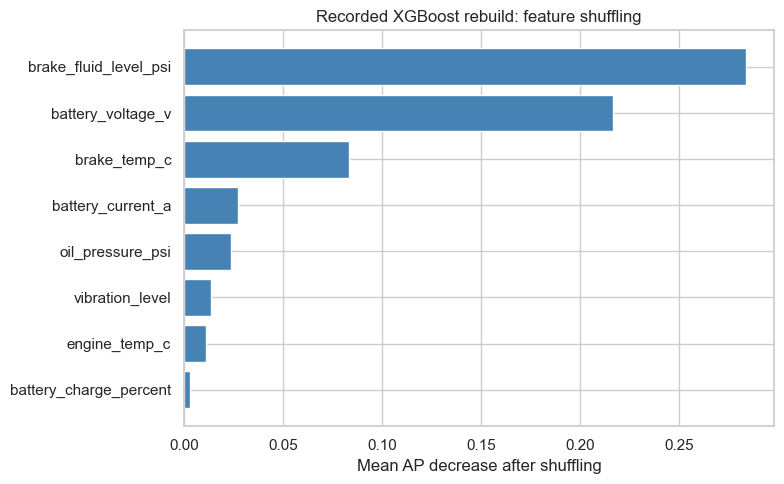

,0
changed_class_rows,"[1249, 1904, 602, 157, 610, 1209, 648]"
exact_cause,unknown; historical runtime and fitted models ...
role,"reproducibility check only, not new tuned mode..."
reconstructed.accuracy,0.996447
reconstructed.average_precision,0.978459
reconstructed.f1,0.90411
reconstructed.f1_is_zero,False
reconstructed.false_negatives,2
reconstructed.false_positives,5
reconstructed.positive_predictions,38


In [18]:
importance = pd.read_csv(recorded / "feature_importance.csv")
importance = importance.loc[importance.scheme.eq("within_vehicle") & importance.kind.eq("individual")]
top = importance.nlargest(8, "average_precision_drop_mean").sort_values("average_precision_drop_mean")
plt.figure(figsize=(8, 5))
plt.barh(top.feature, top.average_precision_drop_mean, color="steelblue")
plt.xlabel("Mean AP decrease after shuffling")
plt.title("Recorded XGBoost rebuild: feature shuffling")
plt.tight_layout()
plt.savefig(figures / "recorded_xgb_importance.png", dpi=180)
plt.show()
display(pd.json_normalize(json.loads((recorded / "reconstruction_comparison.json").read_text())).T)


## Trying random readings

I now use the saved models to predict examples. The ANN uses the selected sensors from this notebook. I randomly choose three issue readings and three ordinary readings so both kinds are visible.

Each reading is scored by the model fitted while its whole vehicle was held out. Random sampling provides different examples. The fitted parameters remain unchanged.


In [19]:
random = np.random.default_rng()
example_rows = np.concatenate([random.choice(df.index[df[target].eq(label)], size=3, replace=False) for label in [0, 1]])
examples = df.loc[example_rows].copy()
display(examples[["vehicle_id", "oil_pressure_psi", "brake_fluid_level_psi", "battery_voltage_v", target]].round(3))
example_configs = [config for config in baseline_configs if config["model"] != "ANN"] + [selected_ann]
example_scores = pd.DataFrame(index=example_rows)
fits_before = FIT_COUNT
for config in example_configs:
    for fold in fold_for_row.loc[example_rows].unique():
        rows = [row for row in example_rows if fold_for_row.loc[row] == fold]
        saved = joblib.load(project / "models" / config["folder"] / config["id"] / f"fold_{int(fold)}.joblib")
        assert set(rows).issubset(saved["test_rows"])
        assert set(rows).isdisjoint(saved["training_rows"])
        example_scores.loc[rows, config["name"]] = predict(saved["model"], df.loc[rows], config)
example_labels = (example_scores >= .5).astype(int)
example_labels.insert(0, "Actual label", df.loc[example_rows, target])
display(example_labels)
display(example_scores.round(4))
assert FIT_COUNT == fits_before
print("0 = ordinary reading; 1 = issue-labelled reading. No models were retrained.")


,vehicle_id,oil_pressure_psi,brake_fluid_level_psi,battery_voltage_v,any_imminent_issue
1455,VEH0037,53.020,999.299,12.999,0
214,VEH0005,39.084,1019.348,12.325,0
215,VEH0005,52.672,1022.688,12.192,0
1926,VEH0049,50.263,463.170,12.431,1
190,VEH0005,30.549,551.816,13.081,1
638,VEH0016,62.951,793.153,9.855,1


,Actual label,Logistic Regression,Random Forest,XGBoost,SVM,Naive Bayes,ANN + selected sensors
1455,0,0,0,0,0,0,0
214,0,0,0,0,0,0,0
215,0,0,0,0,0,0,0
1926,1,1,1,1,1,1,1
190,1,1,0,1,1,1,1
638,1,1,0,1,1,1,1


,Logistic Regression,Random Forest,XGBoost,SVM,Naive Bayes,ANN + selected sensors
1455,0.0031,0.0161,0.0023,0.0001,0.0000,0.0000
214,0.0003,0.0370,0.0028,0.0000,0.0014,0.0000
215,0.1426,0.0503,0.0028,0.0000,0.0152,0.0001
1926,0.9968,0.5602,0.9944,0.9999,1.0000,1.0000
190,0.9981,0.4920,0.9946,0.9994,1.0000,1.0000
638,0.9924,0.3562,0.9802,0.9967,0.9965,0.9996


0 = ordinary reading; 1 = issue-labelled reading. No models were retrained.


## Comparing predictions with the supplied labels

The heatmap makes disagreements easier to see. The scores help explain whether a prediction lies near the 0.5 cutoff. They have not been established as failure probabilities for a real fleet.


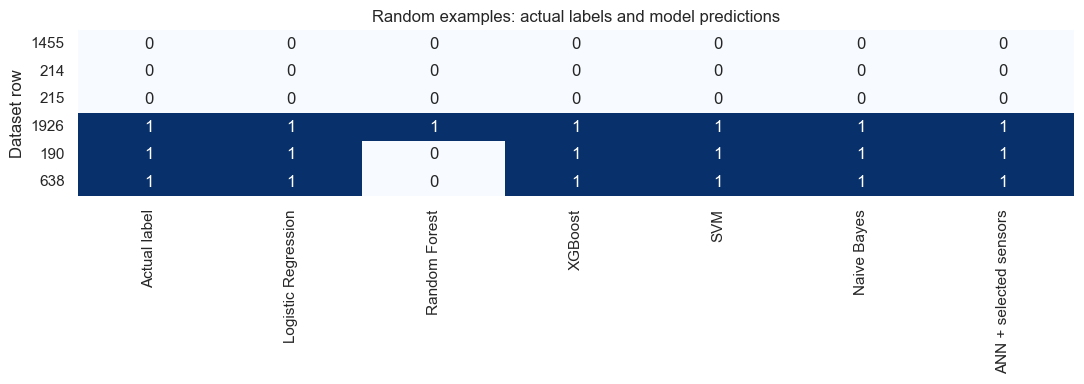

In [20]:
plt.figure(figsize=(11, 4))
sns.heatmap(example_labels, annot=True, fmt="d", cmap="Blues", cbar=False, vmin=0, vmax=1)
plt.xlabel("")
plt.ylabel("Dataset row")
plt.yticks(rotation=0)
plt.title("Random examples: actual labels and model predictions")
plt.tight_layout()
plt.savefig(figures / "random_examples.png", dpi=180)
plt.show()


## Examining the mistakes across the whole dataset

The random examples are a small illustration. I use all out-of-fold predictions below to inspect the actual mistakes for XGBoost and the selected ANN.


In [21]:
error_tables = []
for config in [experiment("XGB"), selected_ann]:
    p = pd.read_csv(project / "results/predictions" / f"{config['id']}.csv")
    errors = p.loc[p.actual.ne(p.predicted)].copy()
    errors["Model"] = config["name"]
    errors["Error"] = np.where(errors.actual.eq(1), "Missed issue", "False alert")
    error_tables.append(errors)
errors = pd.concat(error_tables, ignore_index=True)
display(errors[["Model", "row_index", "vehicle_id", "actual", "score", "predicted", "Error"]].round(4))
errors.to_csv(tables / "leading_model_errors.csv", index=False)


,Model,row_index,vehicle_id,actual,score,predicted,Error
0,XGBoost,157,VEH0004,1,0.0407,0,Missed issue
1,XGBoost,602,VEH0015,0,0.5377,1,False alert
2,XGBoost,610,VEH0016,0,0.9616,1,False alert
3,XGBoost,1087,VEH0028,0,0.7698,1,False alert
4,XGBoost,1143,VEH0029,0,0.5411,1,False alert
5,XGBoost,1239,VEH0032,0,0.7253,1,False alert
6,XGBoost,1249,VEH0032,0,0.7662,1,False alert
7,XGBoost,1911,VEH0048,0,0.7228,1,False alert
8,ANN + selected sensors,1784,VEH0045,0,0.9960,1,False alert
9,ANN + selected sensors,1904,VEH0048,1,0.4174,0,Missed issue


## Final observations

The study compares six model families and follows up with feature selection, PCA, ABS sensitivity and sampling. The recorded report found that selected sensors helped the ANN. The tested sampling methods did not surpass weighted XGBoost on both AP and F1.

The model comparisons and individual predictions show both correct classifications and mistakes. Recorded study results and subsequent fits are presented separately. The synthetic labels and small number of issue readings limit conclusions about real breakdown warnings.
